# Assignment 1: Introduction to the Fully Recurrent Network

*Author:* Thomas Adler

*Copyright statement:* This  material,  no  matter  whether  in  printed  or  electronic  form,  may  be  used  for  personal  and non-commercial educational use only.  Any reproduction of this manuscript, no matter whether as a whole or in parts, no matter whether in printed or in electronic form, requires explicit prior acceptance of the authors.


## Exercise 1: Numerical stability of the binary cross-entropy loss function

We will use the binary cross-entropy loss function to train our RNN, which is defined as 
$$
L_{\text{BCE}}(\hat y, y) = -y \log \hat y - (1-y) \log (1-\hat y),
$$
where $y$ is the label and $\hat y$ is a prediction, which comes from a model (e.g. an RNN) and is usually sigmoid-activated, i.e., we have
$$
\hat y = \sigma(z) = \frac{1}{1+e^{-z}}.
$$
The argument $z$ is called *logit*. For reasons of numerical stability it is better to let the model emit the logit $z$ (instead of the prediction $\hat y$) and incorporate the sigmoid activation into the loss function. Explain why this is the case and how we can gain numerical stability by combining the two functions $L_{\text{BCE}}(\hat y, y)$ and $\sigma(z)$ into one function $L(z, y) = L_{\text{BCE}}(\sigma(z), y)$. 

*Hint: Prove that $\log(1+e^{z}) = \log (1+e^{-|z|}) + \max(0, z)$ and argue why the right-hand side is numerically more stable. Finally, express $L(z,y)$ in terms of that form.*

########## YOUR SOLUTION HERE ##########

When $z \geq 0$, we get:

$e^{-|z|} = e^{-z}$

$\log(1+e^{z}) = \log(e^{z}e^{-z} + e^{z}) = \log(e^{z}(1+e^{-z})) = z + \log(1+e^{-z})$, since $e^{-|z|} = e^{-z}$ and $\max(0,z) = z$, we get:

$\log(1+e^{z}) = z + \log(1+e^{-|z|})$

When $z < 0$, we get:

$e^{-|z|} = e^{z}$

$\log(1+e^{z}) = \log(1 + e^{z}) + \max(0,z)$, since $e^{-|z|} = e^{z}$ and $\max(0,z) = 0$, we get:

$\log(1+e^{z}) = \log(1+e^{-|z|}) + 0$

RHS: 

when $z$ is positive and very large, $e^z$ will be extremely large. Adding 1 and taking the $\log$ will give a number that is very close to $e^{z}$, we won't be able to preserve the error term.

For numerical stability part, choosing the RHS, for $L(z,y)$ we get:

$L(z,y) = L_{\text{BCE}}(\sigma(z),y) = -y \log \sigma(z) -(1-y) \log(1-\sigma(z))$

$L(z,y) = -y \log \left(\frac{1}{1+e^{-z}}\right) -(1-y) \log \left(1-\frac{1}{1+e^{-z}}\right)$

$= -y \log \left(\frac{1}{1+e^{-z}}\right) -(1-y) \log \left(\frac{e^{-z}}{1+e^{-z}}\right)$

$= -y \left[\log(1) -\log(1+e^{-z})\right] -(1-y) \left[\log(e^{-z}) -\log(1+e^{-z})\right]$

Since $\log(1) = 0$ and $\log(e^{-z}) = -z$ (as this is natural log: $\ln(e^{-z})$), we get:

$= y \log(1+e^{-z}) -(1-y)(-z -\log(1+e^{-z}))$ 

$= y \log(1+e^{-z}) +(1-y)z +(1-y)\log(1+e^{-z})$ --> combine ylog(1+e^-z) and (1-y)log(1+e^-z)

$= \log(1+e^{-z}) +(1-y)z$

Since $\log(1+e^{-z}) = \log(e^{-z} e^{z} + e^{-z}) = \log(e^{-z}(1+e^{z})) = -z + \log(1+e^{z})$, we get:

$L(z,y) = -z + \log(1+e^{z}) +(1-y)z = \log(1+e^{z}) - yz$

We can formulate the loss function therefore as:

if $z \geq 0$:
$L(z,y) = \log(1+e^{-z}) + z - yz$

if $z < 0$:
$L(z,y) = \log(1+e^{z}) - yz$

Combining both cases, we get:

$L(z,y) = \log(1+e^{-|z|}) + \max(0,z) - yz$



## Exercise 2: Derivative of the loss

Calculate the derivative of the binary cross-entropy loss function $L(z, y)$ with respect to the logit $z$.

########## YOUR SOLUTION HERE ##########

When $z \geq 0$ and $L(z,y) = \log(1+e^{-z}) + (1-y)z$

Derivative of $L(z,y)$ w.r.t $z$:

Using the chain rule $\frac{\partial}{\partial{z}} f(g(z)) = f'(g(z)) \cdot g'(z)$, we get:

$\frac{\partial L}{\partial z} = \frac{\partial}{\partial z} \log(1+e^{-z}) + \frac{\partial}{\partial z}((1-y)z)$

Derivative of the first term ($f'(t) = \frac{1}{t}$ and $g'(z) = -e^{-z}$, derivative of $-z=-1$):

$\frac{\partial}{\partial z} \log(1+e^{-z}) = \frac{1}{1+e^{-z}} \cdot \frac{\partial}{\partial z}(1+e^{-z}) = \frac{1}{1+e^{-z}} \cdot (-e^{-z}) = -\frac{e^{-z}}{1+e^{-z}}$

Derivative of the second term:

$\frac{\partial}{\partial z}((1-y)z) = 1-y$

Combining both, we get:

$\frac{\partial L}{\partial z} = -\frac{e^{-z}}{1+e^{-z}} + 1-y$

$= 1 - \frac{e^{-z}}{1+e^{-z}} -y$

$= \frac{1+e^{-z}-e^{-z}}{1+e^{-z}} -y$

$= \frac{1}{1+e^{-z}} -y$

$= \sigma(z) -y$

When $z < 0$ and $L(z,y) = \log(1+e^{z}) -yz$

Derivative of $L(z,y)$ w.r.t. $z$:

$\frac{e^{z}}{1+e^{z}} -y$

$\frac{e^{z}}{1+e^{z}} = \frac{e^{z}}{e^{-z} e^{z} + e^{z}} = \frac{1}{e^{-z} + 1} = \sigma(z)$

$\frac{\partial L}{\partial z} = \sigma(z) -y$

## Exercise 3: Initializing the network
Consider the fully recurrent network
$$
s(t) = W x(t) + R a(t-1) \\
a(t) = \tanh(s(t)) \\
z(t) = V a(t) \\
\hat y(t) = \sigma(z(t))
$$
for $t \in \mathbb{N}, x(t) \in \mathbb{R}^{D}, s(t) \in \mathbb{R}^{I}, a(t) \in \mathbb{R}^{I}, z(t) \in \mathbb{R}^K, \hat y(t) \in \mathbb{R}^K$ and $W, R, V$ are real matrices of appropriate sizes and $\hat a(0) = 0$. 

*Compared to the lecture notes we choose $f(x) = \tanh(x) = (e^x - e^{-x})(e^x + e^{-x})^{-1}$ and $\varphi(x) = \sigma(x) = (1+e^{-x})^{-1}$. Further, we introduced an auxiliary variable $z(t)$ and transposed the weight matrices.*

Write a function `init` that takes a `model` and integers $D, I, K$ as arguments and stores the matrices $W, R, V$ as members `model.W`, `model.R`, `model.V`, respectively. The matrices should be `numpy` arrays of appropriate sizes and filled with random values that are uniformly distributed between -0.01 and 0.01. 

In [ ]:
%matplotlib inline
import numpy as np
from scipy.special import expit as sigmoid

class Obj(object):
    pass

model = Obj()
T, D, I, K = 10, 3, 5, 1

def init(model, D, I, K):
    ########## YOUR SOLUTION HERE ##########
    model.D = D
    model.I = I
    model.K = K
    model.W = np.random.uniform(-0.01, 0.01, (D,I))
    model.R = np.random.uniform(-0.01, 0.01, (I,I))
    model.V = np.random.uniform(-0.01, 0.01, (I,K))

    #input  -> hidden (D,I)
    #hidden -> hidden (I,I)
    #hidden -> output (I,K)

Obj.init = init
model.init(D, I, K)

## Exercise 4: The forward pass
Implement the forward pass for the fully recurrent network for sequence classification (many-to-one mapping). To this end, write a function `forward` that takes a `model`, a sequence of input vectors `x`, and a label `y` as arguments. The inputs will be represented as a `numpy` array of shape `(T, D)`. It should execute the behavior of the fully recurrent network and evaluate the (numerically stabilized) binary cross-entropy loss at the end of the sequence and return the resulting loss value. Store the sequence of hidden activations $(a(t))_{t=1}^T$ and the logit $z(T)$ into `model.a` and `model.z`, respectively. 

In [2]:
def forward(model, x, y):
    ########## YOUR SOLUTION HERE ##########
    T, D = x.shape #inputs
    I = model.I #input dim
    a = np.zeros((T, I))
    a_init = np.zeros(I)
    for t in range(T):
        s_t = model.W.T @ x[t] + model.R.T @ a_init
        a_t = np.tanh(s_t)
        a[t] = a_t
        a_init = a_t

    z_T = model.V.T @ a_init
    model.a = a
    model.z = z_T
    loss = np.log(1 + np.exp(-np.abs(z_T))) + np.maximum(0, z_T) - y * z_T
    
    return loss.sum()

Obj.forward = forward
model.forward(np.random.uniform(-1, 1, (T, D)), 1)

0.6931525425625157

## Exercise 5: The computational graph

Visualize the computational graph of the fully recurrent network unfolded in time. The graph should show the functional dependencies of the nodes $x(t), a(t), z(t), L(z(t), y(t))$ for $t \in \{1, 2, 3\}$. Use the package `networkx` in combination with `matplotlib` to draw a directed graph with labelled nodes and edges. If you need help take a look at [this guide](https://networkx.org/documentation/stable/tutorial.html). Make sure to arrange the nodes in a meaningful way. 

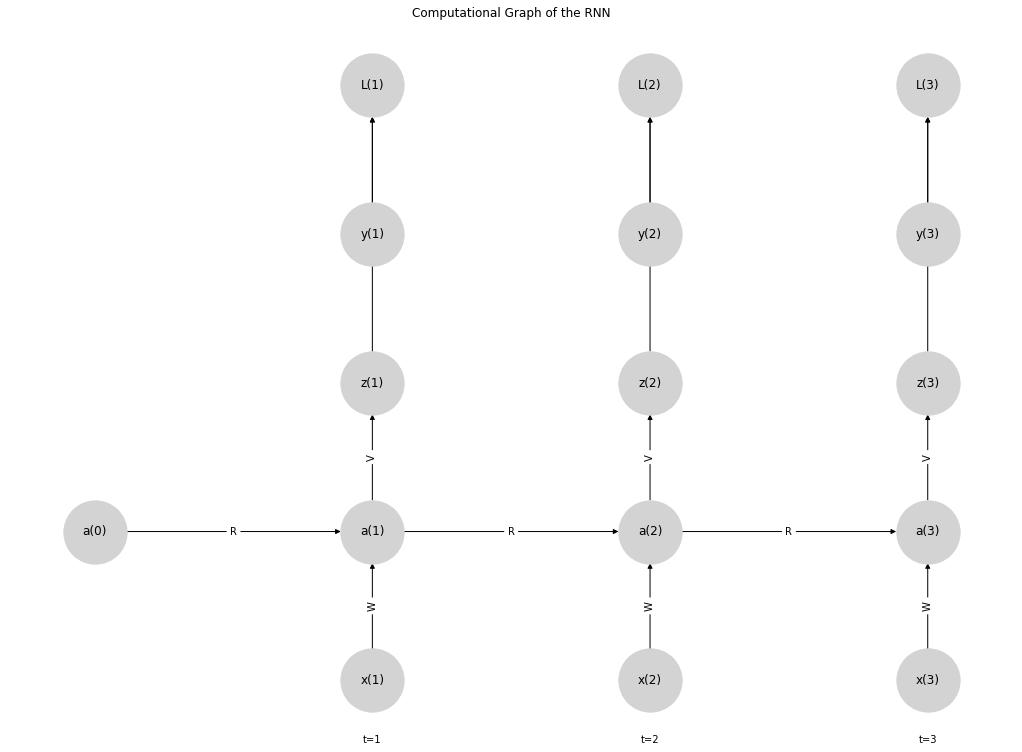

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

########## YOUR SOLUTION HERE ##########
graph = nx.DiGraph()

nodes = ['x(1)', 'x(2)', 'x(3)', 
         'a(0)', 'a(1)', 'a(2)', 'a(3)', 
         'z(1)', 'z(2)', 'z(3)', 
         'y(1)', 'y(2)', 'y(3)', 
         'L(1)', 'L(2)', 'L(3)']

edges = [('x(1)', 'a(1)'), ('a(0)', 'a(1)'), 
         ('x(2)', 'a(2)'), ('a(1)', 'a(2)'), 
         ('x(3)', 'a(3)'), ('a(2)', 'a(3)'), 
         ('a(1)', 'z(1)'), ('a(2)', 'z(2)'), ('a(3)', 'z(3)'),
         ('z(1)', 'L(1)'), ('y(1)', 'L(1)'),
         ('z(2)', 'L(2)'), ('y(2)', 'L(2)'),
         ('z(3)', 'L(3)'), ('y(3)', 'L(3)')]

edge_labels = {
    ('x(1)', 'a(1)'): 'W', ('a(0)', 'a(1)'): 'R',
    ('x(2)', 'a(2)'): 'W', ('a(1)', 'a(2)'): 'R',
    ('x(3)', 'a(3)'): 'W', ('a(2)', 'a(3)'): 'R',
    ('a(1)', 'z(1)'): 'V', ('a(2)', 'z(2)'): 'V', 
    ('a(3)', 'z(3)'): 'V'
}

pos = {
    'L(1)': (1, 3), 'L(2)': (2, 3), 'L(3)': (3, 3),
    'y(1)': (1, 2), 'y(2)': (2, 2), 'y(3)': (3, 2),
    'z(1)': (1, 1), 'z(2)': (2, 1), 'z(3)': (3, 1),
    'a(0)': (0, 0),
    'a(1)': (1, 0), 'a(2)': (2, 0), 'a(3)': (3, 0),
    'x(1)': (1, -1), 'x(2)': (2, -1), 'x(3)': (3, -1)
}

graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

plt.figure(figsize=(14, 10))
nx.draw(graph, pos, with_labels=True, 
        arrows=True, node_size=4000, 
        node_color='lightgray')
nx.draw_networkx_edge_labels(graph, pos, edge_labels)

plt.title("Computational Graph of the RNN")
plt.text(1, -1.4, 't=1', ha='center', va='center')
plt.text(2, -1.4, 't=2', ha='center', va='center')
plt.text(3, -1.4, 't=3', ha='center', va='center')
plt.show()